In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import scripts.common as cmn
import scripts.weight as wght

In [3]:
wght.inspect_weights()

,Модель,Бэкенд,Задача,Статус,Исходные веса,Обученные веса,Файл весов
0,yolov8n,ultralytics,detect,Готово,True,False,yolov8n.pt
1,yolo26n,ultralytics,detect,Готово,True,True,yolo26n.pt


In [4]:
wght.download_weights()

,Статус,Размер (МиБ),Файл
Модель,,,
yolov8n,Уже существует,,yolov8n.pt
yolo26n,Ожидание,,yolo26n.pt


## Реестр и выбор моделей

`cmn.MODELS` остаётся единственным словарём включения и отключения моделей.
`cmn.MODELS_REGESTRY` содержит метаданные реализаций с теми же ключами.
Для семейства необходимо явно указать файл весов: размер модели автоматически
не выбирается. При скачивании используется имя файла из реестра, которое может
отличаться от локального идентификатора модели.

Реализован только бэкенд Ultralytics. Записи MMDetection и RF-DETR зарезервированы
для будущих адаптеров. Остальные реализации отключены и снабжены комментариями.
При обучении неподдерживаемые записи пропускаются с указанием причины;
некорректный датасет или ошибка обучения останавливают выполнение.
Существующие файлы `weights/trained/<model-id>.pt` пропускаются: повторный
запуск обучает только модели, для которых обученные веса ещё не сохранены.


In [5]:
from scripts.contracts import DatasetSpec, TrainConfig, ModelArtifacts
from scripts.workflows import train_models, load_model

# Текущий датасет содержит разметку для детекции. Для сегментации экземпляров
# укажите YAML датасета YOLO с полигональной разметкой и task="segment".
dataset = DatasetSpec(cmn.DATA_YAML, task="detect")
training_config = TrainConfig(
    epochs=5,
    image_size=640,
    batch=1,
    device="cpu",  # При необходимости замените на "cuda:0" или "mps".
    seed=0,
    options={"workers": 0, "plots": True},
)


In [9]:
# Обучаются только включённые модели без файла weights/trained/<model-id>.pt.
RUN_TRAINING = True
training_batch = None
if RUN_TRAINING:
    training_batch = train_models(dataset, training_config)
    print("Completed:", list(training_batch.runs))
    print("Skipped:", training_batch.skipped)
else:
    print("Training disabled. Set RUN_TRAINING=True to execute the five-epoch example.")


New https://pypi.org/project/ultralytics/8.4.212 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.191 🚀 Python-3.14.7 torch-2.14.1+cu130 CPU (12th Gen Intel Core i3-1215U)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/natsusa/academic/tobacco-article/data/tobacco_yolo/data.generated.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=3

## Загрузка результата конкретного запуска и предсказание

Каждый запуск сохраняет лучшие и последние веса, а также `manifest.json`
с описанием модели, версией пакета, фактическими настройками обучения,
хешами датасета и выборок и метриками. Копия в `weights/trained/<model-id>.pt`
содержит веса последнего успешного запуска; для воспроизводимости используйте
артефакт конкретного эксперимента.

Общий интерфейс предсказания принимает путь к локальному изображению, изображение
PIL или массив NumPy формы H×W×3 с типом `uint8` и порядком каналов **BGR**.
Рамки и маски используют координаты исходного изображения. Исходные результаты
провайдера доступны для визуализации.


Рамки: [[     1832.7      249.09        1920      369.24]
 [      397.7      426.15      512.15      532.49]
 [     887.69      789.43      998.47      900.02]
 [     677.43      136.98      802.14      255.53]
 [     213.85      579.09      336.53      689.82]
 [       1028      475.75      1158.2      584.76]
 [     1640.6      570.65      1770.5      650.28]
 [     1445.2      221.71      1570.8      349.56]
 [     911.61      478.33      1015.1      564.87]
 [     689.28      453.09      812.96      554.97]
 [     682.24      778.72      783.03      881.97]
 [     1236.7      504.51      1336.5       614.2]
 [     1452.7      517.47        1570      667.28]
 [     1208.4      851.29      1347.9      963.77]
 [     1646.8      866.85      1767.2      996.35]
 [     222.57      422.64      318.08      526.38]
 [     1817.1      889.08      1913.9      975.07]
 [      899.9      152.96      982.16      246.19]
 [     1031.4      816.76      1148.9      917.26]
 [     211.69      254.6

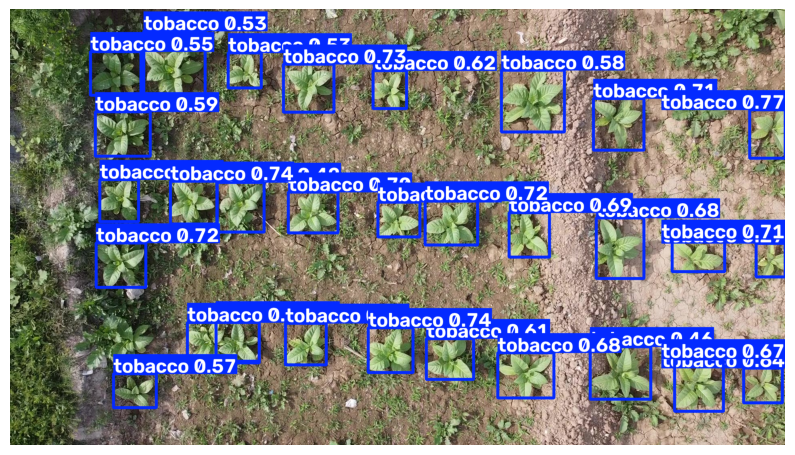

In [10]:
MODEL_TO_INSPECT = "yolo26n"
IMAGE_PATH = cmn.DATASET_PATH / "images" / "00a357bc-17.jpg"

if training_batch is not None and MODEL_TO_INSPECT in training_batch.runs:
    run = training_batch.runs[MODEL_TO_INSPECT]
    predictor = load_model(MODEL_TO_INSPECT, run.best_artifacts, device=training_config.device)
    predictions = predictor.predict(IMAGE_PATH, imgsz=640, conf=0.25)
    for prediction in predictions:
        print("Boxes:", prediction.boxes_xyxy)
        print("Classes:", prediction.class_ids)
        import matplotlib.pyplot as plt
        plt.figure(figsize=(10, 7))
        plt.imshow(prediction.native.plot()[..., ::-1])  # BGR -> RGB
        plt.axis("off")
        plt.show()
else:
    print("Train the chosen model first, or explicitly load an existing run checkpoint.")

# Для загрузки предыдущего запуска укажите точный путь к его весам:
# artifacts = ModelArtifacts(cmn.RUNS_DIR / "<run-name>" / "weights" / "best.pt")
# predictor = load_model(MODEL_TO_INSPECT, artifacts, device=training_config.device)


## Необязательный пример предсказания по подсказкам

Предсказание по подсказкам не зависит от обучения. Адаптер предоставляет
предсказание для SAM, MobileSAM, SAM 2, SAM 3 и FastSAM, но не заявляет
поддержку их обучения через Ultralytics. В нормализованном результате маскам
без семантических классов не назначаются вымышленные идентификаторы классов.

Примеры ниже используют явные спецификации и не изменяют `MODELS`.
По умолчанию выполнение отключено, поскольку файлы весов могут быть большими.
Для SAM 3 может потребоваться ручное получение весов с разрешением доступа:
перед использованием поместите `sam3.pt` в `cmn.ORIGINAL_WEIGHTS_DIR`.


In [8]:
from dataclasses import replace
from scripts.backends import get_backend

RUN_PROMPT_EXAMPLE = False
# Явно задаём вариант семейства SAM; для других семейств используется тот же подход.
prompt_spec = replace(cmn.MODELS_REGESTRY["sam"], checkpoint="sam_b.pt")
if RUN_PROMPT_EXAMPLE:
    backend = get_backend(prompt_spec)
    artifacts = backend.download(prompt_spec)
    prompted = backend.load(prompt_spec, artifacts, device=training_config.device)
    masks = prompted.predict(IMAGE_PATH, prompts={"points": [[100, 100]], "labels": [1]})
    masks[0].native.show()

# Другие виды подсказок (координаты должны соответствовать выбранному изображению):
# YOLOWorld: prompts={"text": ["tobacco", "weed"]}
# YOLOE: prompts={"text": ["tobacco"]}
# YOLOE: prompts={"visual_prompts": {"bboxes": [[10, 10, 100, 100]], "cls": [0]}}
# FastSAM: prompts={"text": ["leaf"]} или {"bboxes": [[10, 10, 100, 100]]}
# SAM/MobileSAM/SAM2/SAM3, интерактивный режим: prompts={"points": [[100, 100]], "labels": [1]}
# SAM3, поиск по понятиям: prompts={"text": ["tobacco"]} или {"exemplars": [[10, 10, 100, 100]]}
# Сопровождение объектов на видео с сохранением состояния не входит в этот API.
